### 02 — Lesion Segmentation using U-Net

What this notebook does:

- load the training, validation, and test splits
- inspect an ultrasound image and its tumour mask
- prepare images and masks for segmentation
- apply synchronised augmentation to the training data
- build and train a U-Net segmentation model
- use BCE + Dice loss to improve lesion overlap
- monitor Dice and IoU during validation
- save the checkpoint with the best validation Dice
- tune the mask threshold using only the validation set
- evaluate the final segmentation model on the held-out test set
- save the selected threshold for use in later notebooks.

The predicted lesion mask is later used to guide the EfficientNet image encoder in the multimodal pipeline.


In [4]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

import random
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode


### 1. Define Project Paths

The notebook uses the existing project folders for the raw ultrasound images, processed dataset splits, and trained model checkpoints.


In [5]:
PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

IMAGE_DIR = RAW_DIR / "images"

### 2. Load the Dataset Splits

The same `train.csv`, `val.csv`, and `test.csv` files created during dataset preparation are loaded here.


In [6]:
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "val.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print(len(train_df), len(val_df), len(test_df))

176 38 38


### 3. Inspect an Ultrasound Image and Tumour Mask

A sample image and its expert-annotated tumour mask are loaded to confirm that both files can be accessed correctly and have matching dimensions.


In [7]:
row = train_df.iloc[13]

image_path = IMAGE_DIR / row["Image_filename"]
mask_path = IMAGE_DIR / row["Mask_tumor_filename"]

image = Image.open(image_path)
mask = Image.open(mask_path)

print("Image size:", image.size)
print("Mask size:", mask.size)

Image size: (761, 572)
Mask size: (761, 572)


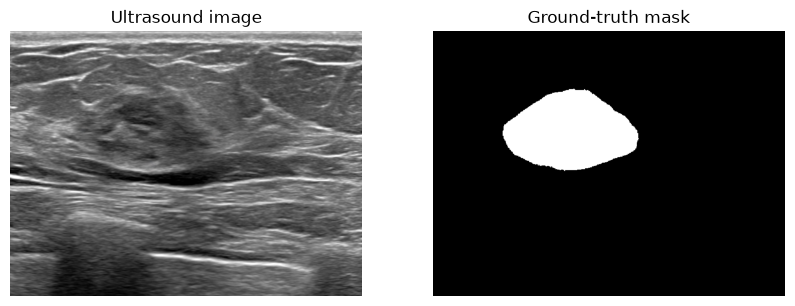

In [8]:
mask_gray = mask.convert("L")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Ultrasound image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_gray, cmap="gray")
plt.title("Ground-truth mask")
plt.axis("off")

plt.show()

### 4. Set the Image Size

All ultrasound images and masks are resized to `224 × 224` pixels so they have a consistent input size for U-Net training.


In [9]:
IMAGE_SIZE = 224

### 5. Create the Segmentation Dataset

The dataset class loads each ultrasound image with its corresponding tumour mask.

The image is converted to grayscale and normalised to values between 0 and 1. The tumour mask is converted into a binary mask.

Augmentation is applied synchronously to the image and mask so that their spatial alignment is preserved:
- horizontal flipping
- small rotations between -10° and +10°

Bilinear interpolation is used for ultrasound images, while nearest-neighbour interpolation is used for masks to preserve the binary labels.


In [10]:
class BreastSegmentationDataset(Dataset):
    def __init__(self, dataframe, image_dir, image_size=224, augment=False):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = self.image_dir / row["Image_filename"]
        mask_path = self.image_dir / row["Mask_tumor_filename"]

        image = Image.open(image_path).convert("L")
        mask = Image.open(mask_path).convert("L")

        # Resize the ultrasound image and mask to the same spatial size.
        # Nearest-neighbour interpolation is used for masks to preserve labels.
        image = image.resize(
            (self.image_size, self.image_size),
            Image.BILINEAR
        )

        mask = mask.resize(
            (self.image_size, self.image_size),
            Image.NEAREST
        )

        image = np.array(image, dtype=np.float32) / 255.0
        mask = np.array(mask, dtype=np.float32)

        # Convert the ground-truth mask to binary values: background=0, lesion=1.
        mask = (mask > 0).astype(np.float32)

        # Add the channel dimension expected by PyTorch: [1, H, W].
        image = torch.tensor(image).unsqueeze(0)
        mask = torch.tensor(mask).unsqueeze(0)

        # Training-only augmentation. Geometric transformations must be applied
        # identically to the image and mask so that they remain aligned.
        if self.augment:

            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            angle = random.uniform(-10, 10)

            image = TF.rotate(
                image,
                angle,
                interpolation=InterpolationMode.BILINEAR
            )

            mask = TF.rotate(
                mask,
                angle,
                interpolation=InterpolationMode.NEAREST
            )

        return image, mask

### 6. Create Datasets and Data Loaders

Augmentation is enabled only for the training set.

The validation and test sets are not augmented so that model performance is measured on the original images.


In [11]:
train_dataset = BreastSegmentationDataset(
    train_df,
    IMAGE_DIR,
    IMAGE_SIZE,
    augment=True
)

val_dataset = BreastSegmentationDataset(
    val_df,
    IMAGE_DIR,
    IMAGE_SIZE,
    augment=False
)

test_dataset = BreastSegmentationDataset(
    test_df,
    IMAGE_DIR,
    IMAGE_SIZE,
    augment=False
)

In [12]:
image_tensor, mask_tensor = train_dataset[0]

print(image_tensor.shape)
print(mask_tensor.shape)
print(image_tensor.min(), image_tensor.max())
print(mask_tensor.unique())

torch.Size([1, 224, 224])
torch.Size([1, 224, 224])
tensor(0.0021) tensor(0.9478)
tensor([0., 1.])


In [13]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

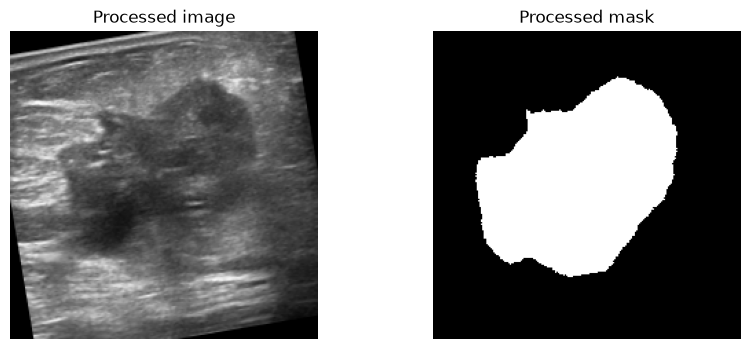

In [14]:
image, mask = train_dataset[0]

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image.squeeze(), cmap="gray")
plt.title("Processed image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask.squeeze(), cmap="gray")
plt.title("Processed mask")
plt.axis("off")

plt.show()

### 7. Build the U-Net Model

U-Net is used to predict a binary lesion mask from each ultrasound image.

The architecture contains:
- an encoder that progressively extracts image features
- a bottleneck containing the deepest feature representation
- a decoder that restores the spatial resolution
- skip connections that pass information from the encoder to the decoder.

Each stage uses a reusable double-convolution block with convolution, batch normalisation, and ReLU activation.


In [15]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [16]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(1, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.bottleneck = DoubleConv(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.output = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)

        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.output(d1)

Test using a dummy tensor to make sure that a 224 × 224 input produces an output mask with the expected dimensions.


In [17]:
model = UNet()

dummy = torch.randn(2, 1, 224, 224)
output = model(dummy)

print(output.shape)

torch.Size([2, 1, 224, 224])


### 8. Define the Segmentation Loss

The model uses a combination of Binary Cross-Entropy and Dice loss.

- **Binary Cross-Entropy** provides pixel-level supervision.
- **Dice loss** encourages overlap between the predicted lesion region and the expert mask.

The two losses are weighted equally.


In [18]:
bce_loss = nn.BCEWithLogitsLoss()

In [19]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)

        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)

        intersection = (probs * targets).sum(dim=1)

        dice = (2.0 * intersection + self.smooth) / (
            probs.sum(dim=1)+ targets.sum(dim=1)+ self.smooth
        )
        return 1 - dice.mean()

In [20]:
dice_loss = DiceLoss()


def segmentation_loss(logits, targets):
    return (0.5 * bce_loss(logits, targets)+ 0.5 * dice_loss(logits, targets))

### 9. Define the Evaluation Metrics

Segmentation performance is measured using:
- Dice coefficient — measures overlap between the predicted and ground-truth lesion masks.
- Intersection over Union (IoU) — measures the intersection of the two masks relative to their union.

A threshold of 0.5 is used during training and validation monitoring. The final threshold is tuned later using the validation set only.


In [21]:
def dice_score(logits, targets, threshold=0.5, eps=1e-7):
    preds = torch.sigmoid(logits)
    preds = (preds > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))

    denominator = (
        preds.sum(dim=(1, 2, 3))
        + targets.sum(dim=(1, 2, 3))
    )

    dice = (2 * intersection + eps) / (denominator + eps)

    return dice.mean()

In [22]:
def iou_score(logits, targets, threshold=0.5, eps=1e-7):
    preds = torch.sigmoid(logits)
    preds = (preds > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))

    union = (
        preds.sum(dim=(1, 2, 3))
        + targets.sum(dim=(1, 2, 3))
        - intersection
    )

    iou = (intersection + eps) / (union + eps)

    return iou.mean()

### 10. Configure Model Training

The model uses the GPU when CUDA is available.

AdamW is used as the optimiser with a learning rate of 1e-4 and weight decay for regularisation.

ReduceLROnPlateau lowers the learning rate when validation Dice stops improving.


In [23]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

model = UNet().to(device)

cuda


In [24]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Reduce the learning rate when validation Dice stops improving.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

### 11. Train the U-Net

The model is trained for a maximum of 50 epochs.

Early stopping is used with a patience of 5 epochs. If validation Dice does not improve for 5 consecutive epochs, training stops.

The checkpoint with the highest validation Dice is saved as `best_unet.pth`


In [25]:
EPOCHS = 50
PATIENCE = 5

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_unet.pth"

In [26]:
train_losses = []
val_losses = []
val_dice_scores = []
val_iou_scores = []
learning_rates = []

best_val_dice = -1.0
patience_counter = 0

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    model.train()
    running_train_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = segmentation_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    running_val_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            # Use the same BCE + Dice objective for validation.
            loss = segmentation_loss(outputs, masks)

            running_val_loss += loss.item()
            running_dice += dice_score(outputs, masks, threshold=0.5).item()
            running_iou += iou_score(outputs, masks, threshold=0.5).item()

    val_loss = running_val_loss / len(val_loader)
    val_dice = running_dice / len(val_loader)
    val_iou = running_iou / len(val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_dice_scores.append(val_dice)
    val_iou_scores.append(val_iou)
    learning_rates.append(optimizer.param_groups[0]["lr"])

    # Update the learning rate based on validation Dice.
    scheduler.step(val_dice)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Dice: {val_dice:.4f} | "
        f"IoU: {val_iou:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.2e}"
    )

    # Save the checkpoint with the best validation Dice.
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        patience_counter = 0

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print(f"Best model saved (validation Dice = {best_val_dice:.4f})")

    else:
        patience_counter += 1
        print(f"No Dice improvement ({patience_counter}/{PATIENCE})")

        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

print(f"Best validation Dice: {best_val_dice:.4f}")

Epoch 01/50 | Train Loss: 0.7051 | Val Loss: 0.7063 | Dice: 0.0000 | IoU: 0.0000 | LR: 1.00e-04
Best model saved (validation Dice = 0.0000)
Epoch 02/50 | Train Loss: 0.6191 | Val Loss: 0.6378 | Dice: 0.3685 | IoU: 0.2669 | LR: 1.00e-04
Best model saved (validation Dice = 0.3685)
Epoch 03/50 | Train Loss: 0.5714 | Val Loss: 0.5564 | Dice: 0.4715 | IoU: 0.3512 | LR: 1.00e-04
Best model saved (validation Dice = 0.4715)
Epoch 04/50 | Train Loss: 0.5342 | Val Loss: 0.5159 | Dice: 0.5450 | IoU: 0.4164 | LR: 1.00e-04
Best model saved (validation Dice = 0.5450)
Epoch 05/50 | Train Loss: 0.5112 | Val Loss: 0.5167 | Dice: 0.5624 | IoU: 0.4389 | LR: 1.00e-04
Best model saved (validation Dice = 0.5624)
Epoch 06/50 | Train Loss: 0.4955 | Val Loss: 0.5036 | Dice: 0.5532 | IoU: 0.4158 | LR: 1.00e-04
No Dice improvement (1/5)
Epoch 07/50 | Train Loss: 0.4787 | Val Loss: 0.5198 | Dice: 0.5033 | IoU: 0.3924 | LR: 1.00e-04
No Dice improvement (2/5)
Epoch 08/50 | Train Loss: 0.4672 | Val Loss: 0.4775 | Di

### 12. Review the Training Curves


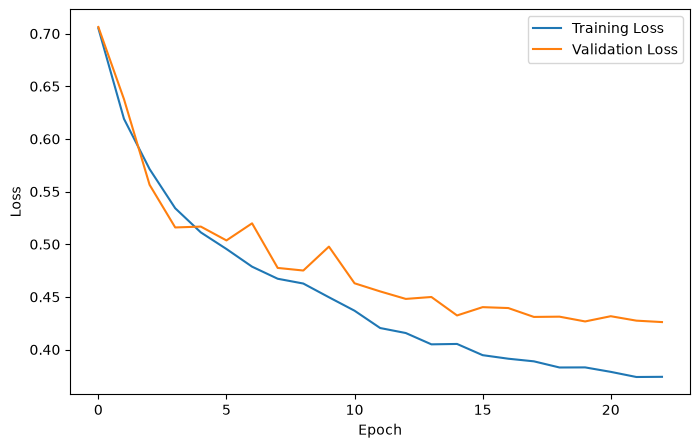

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

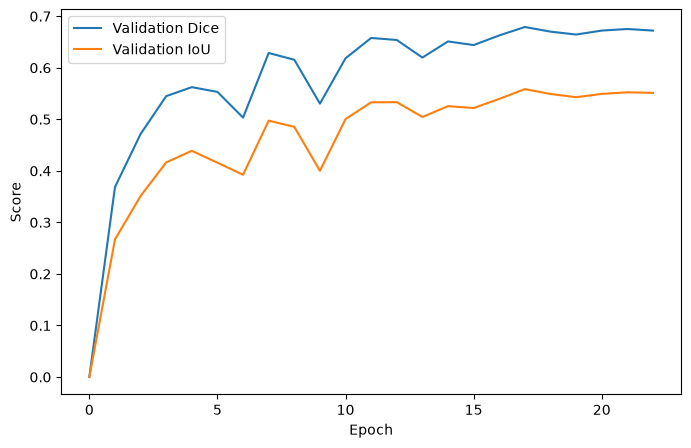

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(val_dice_scores, label="Validation Dice")
plt.plot(val_iou_scores, label="Validation IoU")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.legend()

plt.show()

### 13. Load the Best Model and Inspect a Prediction

The checkpoint with the highest validation Dice is reloaded and a validation image is passed through the model to compare the predicted lesion mask with the expert ground-truth mask.


In [35]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)
model.eval()

image, mask = val_dataset[9]

with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))

prediction = torch.sigmoid(output)
prediction = (prediction > 0.5).float()
prediction = prediction.squeeze().cpu()

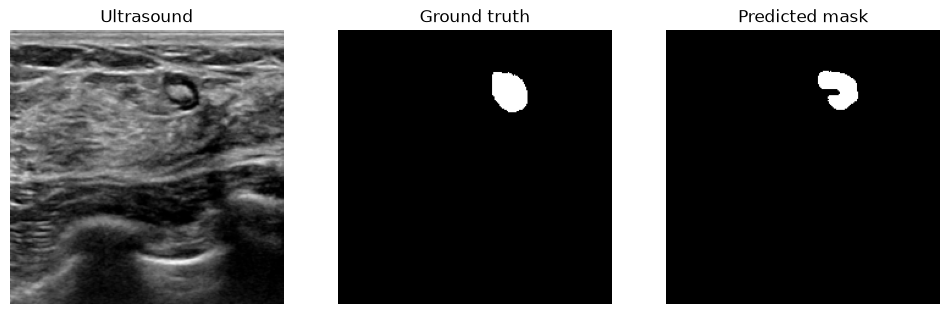

In [36]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image.squeeze(), cmap="gray")
plt.title("Ultrasound")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask.squeeze(), cmap="gray")
plt.title("Ground truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction, cmap="gray")
plt.title("Predicted mask")
plt.axis("off")

plt.show()

### 14. Tune the Segmentation Threshold

Several thresholds from 0.30 to 0.70 are tested using the validation set. The threshold with the highest mean validation Dice is selected as `BEST_THRESHOLD`.


In [37]:
thresholds = np.arange(0.30, 0.71, 0.05)
threshold_results = []

model.eval()

with torch.no_grad():
    for threshold in thresholds:
        dice_values = []
        iou_values = []

        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)

            dice_values.append(
                dice_score(logits, masks, threshold=float(threshold)).item()
            )
            iou_values.append(
                iou_score(logits, masks, threshold=float(threshold)).item()
            )

        threshold_results.append({
            "threshold": float(threshold),
            "dice": float(np.mean(dice_values)),
            "iou": float(np.mean(iou_values))
        })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

best_row = threshold_df.loc[threshold_df["dice"].idxmax()]
BEST_THRESHOLD = float(best_row["threshold"])

print(f"Best validation threshold: {BEST_THRESHOLD:.2f}")
print(f"Validation Dice at best threshold: {best_row['dice']:.4f}")
print(f"Validation IoU at best threshold: {best_row['iou']:.4f}")

,threshold,dice,iou
0,0.30,0.661426,0.538239
1,0.35,0.667640,0.545572
2,0.40,0.672191,0.550944
3,0.45,0.676355,0.555601
4,0.50,0.679112,0.558607
5,0.55,0.679832,0.559490
6,0.60,0.679292,0.558645
7,0.65,0.677672,0.556199
8,0.70,0.672102,0.549265


Best validation threshold: 0.55
Validation Dice at best threshold: 0.6798
Validation IoU at best threshold: 0.5595


The selected threshold is saved to `models/segmentation_config.json` so that the same value can be loaded by the later image-encoding, classification, integration, and inference stages.


In [38]:
import json

threshold_config = {
    "best_threshold": float(BEST_THRESHOLD)
}

with open(
    MODEL_DIR / "segmentation_config.json",
    "w"
) as f:
    json.dump(
        threshold_config,
        f,
        indent=4
    )

print(
    "Saved BEST_THRESHOLD:",
    BEST_THRESHOLD
)

Saved BEST_THRESHOLD: 0.5499999999999999


### 15. Visualise a Prediction using the Selected Threshold

A second validation example is displayed using `BEST_THRESHOLD`


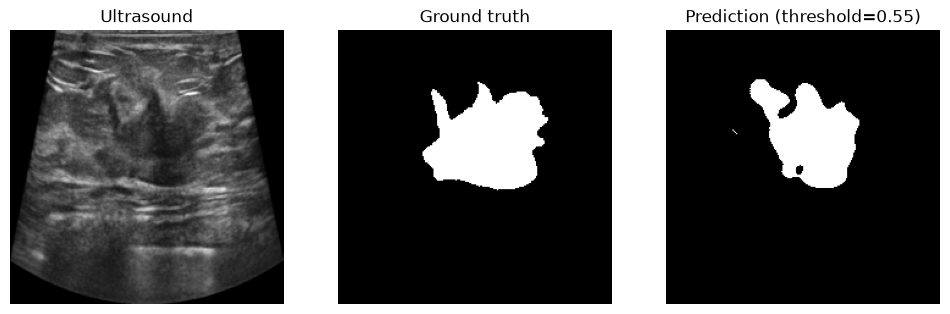

In [43]:
image, mask = val_dataset[16]

with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))

prediction = (
    torch.sigmoid(output) >= BEST_THRESHOLD
).float().squeeze().cpu()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image.squeeze(), cmap="gray")
plt.title("Ultrasound")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask.squeeze(), cmap="gray")
plt.title("Ground truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction, cmap="gray")
plt.title(f"Prediction (threshold={BEST_THRESHOLD:.2f})")
plt.axis("off")

plt.show()

### 16. Evaluate the Final Model on the Test Set

After model selection and threshold tuning are complete, the saved U-Net is evaluated on the held-out test set.

The final mean Dice and IoU scores from this section are used as the reported segmentation performance.


In [34]:
test_dice_scores = []
test_iou_scores = []

model.eval()

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)

        test_dice_scores.append(
            dice_score(logits, masks, threshold=BEST_THRESHOLD).item()
        )
        test_iou_scores.append(
            iou_score(logits, masks, threshold=BEST_THRESHOLD).item()
        )

print(f"Final test Dice: {np.mean(test_dice_scores):.4f}")
print(f"Final test IoU:  {np.mean(test_iou_scores):.4f}")

Final test Dice: 0.7427
Final test IoU:  0.6227


### 17. Outputs from this Notebook

The main outputs are:

- `models/best_unet.pth` — U-Net checkpoint with the highest validation Dice
- `models/segmentation_config.json` — validation-selected segmentation threshold
- final test Dice and IoU scores.

The saved model and threshold are used in the later multimodal pipeline so that new ultrasound images can be segmented automatically during inference.
